# Forecasting Monthly New Vehicle Price Changes

## Question
Can macroeconomic indicators and recent price momentum forecast next month's change in the US new vehicle CPI, and do recession or COVID shocks add predictive value?

## Data
FRED monthly data, May 1974 to December 2024 (608 observations). Target: percent change in the new vehicle CPI. Predictors, all lagged one month: percent changes in the used vehicle CPI, real disposable income per capita, and headline CPI; previous-quarter growth in real GDP per capita; the monthly change in the employment-population ratio; and the previous month's new vehicle change. The sample starts in mid-1974, after the end of the 1971-74 wage and price controls and the end of the gold standard.

## Method
- Models: OLS, ridge, and gradient boosting (GBM).
- Validation: rolling-origin cross-validation (origins 2000, 2005, 2010, 2015, 2020, 2021), training on all data to each origin and validating on the next 12 months.
- Holdout: January 2023 to December 2024, scored after model selection.
- Metrics: MAE and RMSE in percentage points.
- Baselines: the training-set mean change, and last month's change.
- Levels vs changes: raw and log levels scored far worse (MAE 3.61 and 3.32 vs 0.34) with ADF p-values of 0.76 and 0.38 and Durbin-Watson near 0.1, the signature of spurious regression, so the models use percent changes.

## Results
| Model | CV MAE | CV RMSE |
|---|---|---|
| Naive: training mean | 0.3803 | n/a |
| Naive: last month | 0.2389 | 0.3402 |
| OLS | 0.2670 | 0.3280 |
| Ridge | 0.2712 | 0.3285 |
| GBM | 0.2450 | 0.3125 |

Holdout (2023-24): GBM MAE 0.1371 and RMSE 0.1725, vs 0.2229 (mean) and 0.1429 (last month).

## Findings
- GBM has the lowest CV error and beats the mean baseline in all six folds. Against the last-month baseline it is comparable on MAE and better on RMSE.
- Most predictive power comes from price momentum. A model using only last month's change (MAE 0.2654) matches OLS with all predictors (0.2670).
- In the HAC-robust OLS, lagged new vehicle change (p < 0.001), headline CPI (p < 0.001), and used vehicle CPI (p = 0.003) are significant. Income and GDP are not.
- Recession and COVID dummies gave no out-of-sample benefit (CV MAE 0.2670 to 0.2680) and were not significant, apart from 1981 (p = 0.081).

## Limitations
- The CV folds overlap, and the holdout has 24 months, so small gaps are not resolvable.
- The holdout was viewed during earlier model iterations.
- The percent-change target is borderline stationary (ADF p = 0.066).
- GBM hyperparameters were not tuned. Monthly changes remain mostly unpredictable.
- Forecasts are one month ahead.

## Conclusion
Monthly new vehicle price changes are persistent. A GBM using macro indicators and last month's change forecasts them better than a mean baseline and about as well as, or slightly better than, a persistence baseline. Event dummies add nothing out of sample.

## Setup

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from dotenv import load_dotenv
from fredapi import Fred
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.stattools import adfuller

load_dotenv("../.env")  # FRED_API_KEY lives in .env, not in the notebook
fred = Fred(api_key=os.environ["FRED_API_KEY"])

TARGET = "new_vehicle"
BASE = ["used_vehicle", "income", "cpi_all", "emp_pp", "gdp"]
FEATURES = BASE + ["new_vehicle_lag1"]       # predictors lagged one month, plus own lag

START, END = "1974-05-01", "2024-12-01"
DEV_END, TEST_START = "2022-12-01", "2023-01-01"
ORIGINS = ["2000-12-01", "2005-12-01", "2010-12-01", "2015-12-01", "2020-12-01", "2021-12-01"]
HORIZON = 12                                  # months validated per fold

SERIES = {
    "new_vehicle_cpi": "CUSR0000SETA01",
    "used_vehicle_cpi": "CUSR0000SETA02",
    "real_gdp_pc": "A939RX0Q048SBEA",         # quarterly
    "emp_pop_ratio": "EMRATIO",
    "real_disp_income_pc": "A229RX0",         # monthly series (the annual one is A229RX0A048NBEA)
    "cpi_all": "CPIAUCSL",
}

## Data
Monthly data gives far more observations than annual data, at the cost of more noise. The sample starts in mid-1974, after the end of the 1971-74 wage and price controls and the end of the gold standard.

In [2]:
def month_start(s):
    """Align a FRED series to month-start timestamps."""
    s = s.copy()
    s.index = s.index.to_period("M").to_timestamp()
    return s

raw = {name: month_start(fred.get_series(sid)) for name, sid in SERIES.items()}
pd.DataFrame(raw).to_csv("raw_fred_snapshot.csv")   # snapshot of exactly what the models use

df_m = pd.DataFrame(raw).drop(columns="real_gdp_pc").loc[START:END].dropna()
print(len(df_m), "monthly observations;", df_m.index.min().date(), "to", df_m.index.max().date())
print(df_m.index.to_series().diff().value_counts().head())   # calendar-day gaps (28-31 expected)
df_m.head()

608 monthly observations; 1974-05-01 to 2024-12-01
31 days    354
30 days    203
28 days     37
29 days     13
Name: count, dtype: int64


,new_vehicle_cpi,used_vehicle_cpi,emp_pop_ratio,real_disp_income_pc,cpi_all
1974-05-01,56.6,34.1,58.0,20743.0,48.6
1974-06-01,57.5,35.7,58.0,20684.0,49.0
1974-07-01,58.6,36.9,58.0,20746.0,49.3
1974-08-01,59.0,38.1,57.8,20699.0,49.9
1974-09-01,59.8,39.3,57.7,20658.0,50.6


## Features
Percent changes for price and income series, first difference for the employment-population ratio, and the previous quarter's real GDP growth. Shock dummies mark the 1981 recession, the 2008 recession, and COVID.

In [3]:
SHOCKS = {
    "recession_1981": ("1981-07-01", "1982-11-01"),
    "recession_2008": ("2007-12-01", "2009-06-01"),
    "covid": ("2020-03-01", "2020-12-01"),
}

pchg = pd.DataFrame(index=df_m.index)
for name, col in {"new_vehicle": "new_vehicle_cpi", "used_vehicle": "used_vehicle_cpi",
                  "income": "real_disp_income_pc", "cpi_all": "cpi_all"}.items():
    pchg[name] = df_m[col].pct_change() * 100
pchg["emp_pp"] = df_m["emp_pop_ratio"].diff()

# Quarterly GDP growth, shifted one quarter, forward-filled to months
gdp_growth = (raw["real_gdp_pc"].pct_change() * 100).shift(1)
pchg["gdp"] = gdp_growth.reindex(df_m.index, method="ffill")

for name, (start, end) in SHOCKS.items():
    pchg[name] = 0
    pchg.loc[start:end, name] = 1
pchg = pchg.dropna()

# Sanity check: months flagged per shock and the date range covered
print(pd.DataFrame({n: {"months": int(pchg[n].sum()),
                        "first": pchg.index[pchg[n] == 1].min().date(),
                        "last": pchg.index[pchg[n] == 1].max().date()} for n in SHOCKS}).T)

               months       first        last
recession_1981     17  1981-07-01  1982-11-01
recession_2008     19  2007-12-01  2009-06-01
covid              10  2020-03-01  2020-12-01


## Forecast dataset
All predictors are lagged one month so each row uses only information available the month before. Development data runs through December 2022. January 2023 to December 2024 is the holdout.

In [4]:
data = pchg.copy()
for c in BASE:
    data[c] = pchg[c].shift(1)
data["new_vehicle_lag1"] = pchg[TARGET].shift(1)
data = data.dropna()

dev, test = data.loc[:DEV_END], data.loc[TEST_START:]

## Cross-validation helpers

In [5]:
def rmse(y, p):
    return np.sqrt(mean_squared_error(y, p))

def folds(d):
    """Rolling-origin splits: train through each origin, validate on the next HORIZON months."""
    for origin in ORIGINS:
        yield origin, d.loc[:origin], d.loc[origin:].iloc[1:HORIZON + 1]

def ols_fit_predict(train, valid, features):
    use = [f for f in features if train[f].nunique() > 1]
    fit = sm.OLS(train[TARGET], sm.add_constant(train[use])).fit()
    return fit.predict(sm.add_constant(valid[use], has_constant="add"))

def sklearn_fit_predict(make_model):
    def fp(train, valid, features):
        return make_model().fit(train[features], train[TARGET]).predict(valid[features])
    return fp

def cv_eval(fit_predict, d, features):
    """Per-fold MAE/RMSE for a model, plus both naive baselines (training mean, last month)."""
    rows = []
    for origin, tr, va in folds(d):
        p = fit_predict(tr, va, features)
        y = va[TARGET]
        mean_pred = [tr[TARGET].mean()] * len(va)
        rows.append({"origin": origin,
                     "mae": mean_absolute_error(y, p), "rmse": rmse(y, p),
                     "naive_mae": mean_absolute_error(y, mean_pred),
                     "last_mae": mean_absolute_error(y, va["new_vehicle_lag1"]),
                     "last_rmse": rmse(y, va["new_vehicle_lag1"])})
    return pd.DataFrame(rows).set_index("origin")

ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
gbm = lambda: GradientBoostingRegressor(n_estimators=100, max_depth=2,
                                        learning_rate=0.05, random_state=0)

## Do shock dummies help out of sample?

In [6]:
variants = {"base": FEATURES}
variants.update({"+" + s: FEATURES + [s] for s in SHOCKS})
variants["all_dummies"] = FEATURES + list(SHOCKS)

dummy_cv = pd.Series({k: cv_eval(ols_fit_predict, dev, f)["mae"].mean() for k, f in variants.items()})
print(dummy_cv.sort_values().round(4))

base               0.2670
+recession_2008    0.2671
+covid             0.2675
+recession_1981    0.2675
all_dummies        0.2680
dtype: float64


## Model comparison (cross-validation)

In [7]:
res_ols = cv_eval(ols_fit_predict, dev, FEATURES)
print(res_ols.round(4))   # per-fold OLS detail

compare = pd.DataFrame({
    "OLS": res_ols.mean(),
    "Ridge": cv_eval(sklearn_fit_predict(ridge), dev, FEATURES).mean(),
    "GBM": cv_eval(sklearn_fit_predict(gbm), dev, FEATURES).mean(),
}).T
print(compare[["mae", "rmse"]].round(4))
print("Baselines (training mean MAE | last-month MAE, RMSE):")
print(compare.iloc[0][["naive_mae", "last_mae", "last_rmse"]].round(4))

               mae    rmse  naive_mae  last_mae  last_rmse
origin                                                    
2000-12-01  0.1896  0.2268     0.3154    0.1527     0.1972
2005-12-01  0.1834  0.2325     0.3205    0.2422     0.2783
2010-12-01  0.1535  0.2216     0.2150    0.1953     0.2443
2015-12-01  0.1558  0.2203     0.2130    0.2278     0.3113
2020-12-01  0.5974  0.6719     0.9099    0.3481     0.5586
2021-12-01  0.3226  0.3949     0.3080    0.2674     0.4511
          mae    rmse
OLS    0.2670  0.3280
Ridge  0.2712  0.3285
GBM    0.2450  0.3125
Baselines (training mean MAE | last-month MAE, RMSE):
naive_mae    0.3803
last_mae     0.2389
last_rmse    0.3402
Name: OLS, dtype: float64


GBM has the lowest CV error (MAE 0.2450, RMSE 0.3125) against OLS (0.2670, 0.3280) and Ridge (0.2712, 0.3285). I use GBM as the forecasting model and keep OLS for interpreting coefficients.

In [8]:
print("GBM, per fold:")
print(cv_eval(sklearn_fit_predict(gbm), dev, FEATURES).round(4))

GBM, per fold:
               mae    rmse  naive_mae  last_mae  last_rmse
origin                                                    
2000-12-01  0.1806  0.2372     0.3154    0.1527     0.1972
2005-12-01  0.1760  0.2348     0.3205    0.2422     0.2783
2010-12-01  0.1722  0.2495     0.2150    0.1953     0.2443
2015-12-01  0.1773  0.2231     0.2130    0.2278     0.3113
2020-12-01  0.4629  0.5544     0.9099    0.3481     0.5586
2021-12-01  0.3011  0.3762     0.3080    0.2674     0.4511


## How much is momentum?
Compares the full model against the same model without the lagged target, and against a lag-only model.

In [9]:
no_lag = cv_eval(ols_fit_predict, dev, BASE)
lag_only = cv_eval(ols_fit_predict, dev, ["new_vehicle_lag1"])
gbm_lag_only = cv_eval(sklearn_fit_predict(gbm), dev, ["new_vehicle_lag1"])

print(pd.DataFrame({
    "OLS, all predictors": res_ols.mean(),
    "OLS, no lagged target": no_lag.mean(),
    "OLS, lagged target only": lag_only.mean(),
    "GBM, lagged target only": gbm_lag_only.mean(),
}).T[["mae", "rmse"]].round(4))

                            mae    rmse
OLS, all predictors      0.2670  0.3280
OLS, no lagged target    0.3358  0.3863
OLS, lagged target only  0.2654  0.3288
GBM, lagged target only  0.2424  0.3066


## Coefficients (HAC-robust OLS)

In [10]:
X = sm.add_constant(dev[FEATURES + list(SHOCKS)])
hac = sm.OLS(dev[TARGET], X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(hac.summary())

                            OLS Regression Results                            
Dep. Variable:            new_vehicle   R-squared:                       0.322
Model:                            OLS   Adj. R-squared:                  0.311
Method:                 Least Squares   F-statistic:                     25.41
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           7.54e-37
Time:                        00:43:04   Log-Likelihood:                -227.51
No. Observations:                 582   AIC:                             475.0
Df Residuals:                     572   BIC:                             518.7
Df Model:                           9                                         
Covariance Type:                  HAC                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.0186      0.022  

## Why percent changes?
Scores the same OLS on raw levels, log levels, and percent changes. Level forecasts are converted back to percent changes so all three are scored on the same scale.

In [11]:
CPI = {"new_vehicle": "new_vehicle_cpi", "used_vehicle": "used_vehicle_cpi",
       "income": "real_disp_income_pc", "cpi_all": "cpi_all"}
TRANSFORMS = {"raw": lambda s: s, "log": np.log, "pct": lambda s: s.pct_change() * 100}
feats4 = [c for c in BASE if c != "gdp"]            # GDP is quarterly; omitted here
actual_pct = df_m["new_vehicle_cpi"].pct_change() * 100
prev_level = df_m["new_vehicle_cpi"].shift(1)

def build(kind):
    d = pd.DataFrame({k: TRANSFORMS[kind](df_m[c]) for k, c in CPI.items()})
    d["emp_pp"] = df_m["emp_pop_ratio"].diff() if kind == "pct" else df_m["emp_pop_ratio"]
    out = pd.concat([d[TARGET], d[feats4].shift(1)], axis=1).dropna()
    return out.loc[data.index[0]:DEV_END]

def to_pct(pred, kind, idx):
    if kind == "raw":
        return (pred / prev_level.loc[idx] - 1) * 100
    if kind == "log":
        return (np.exp(pred) / prev_level.loc[idx] - 1) * 100
    return pred

rows = {}
for kind in TRANSFORMS:
    d = build(kind)
    maes, rmses, naives = [], [], []
    for _, tr, va in folds(d):
        fit = sm.OLS(tr[TARGET], sm.add_constant(tr[feats4])).fit()
        p = to_pct(fit.predict(sm.add_constant(va[feats4], has_constant="add")), kind, va.index)
        act = actual_pct.loc[va.index]
        maes.append(mean_absolute_error(act, p))
        rmses.append(rmse(act, p))
        naives.append(mean_absolute_error(act, [actual_pct.loc[tr.index].mean()] * len(va)))
    full = sm.OLS(d[TARGET], sm.add_constant(d[feats4])).fit()
    rows[kind] = {"mae": np.mean(maes), "rmse": np.mean(rmses), "naive_mae": np.mean(naives),
                  "adf_p": adfuller(d[TARGET])[1], "durbin_watson": durbin_watson(full.resid)}
print(pd.DataFrame(rows).T.round(4))

        mae    rmse  naive_mae   adf_p  durbin_watson
raw  3.6138  3.8459     0.3803  0.7594         0.1469
log  3.3174  3.5434     0.3803  0.3794         0.1078
pct  0.3372  0.3885     0.3803  0.0659         1.2334


/tmp/ipykernel_100619/118956392.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "adf_p": adfuller(d[TARGET])[1], "durbin_watson": durbin_watson(full.resid)}
/tmp/ipykernel_100619/118956392.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "adf_p": adfuller(d[TARGET])[1], "durbin_watson": durbin_watson(full.resid)}
/tmp/ipykernel_100619/118956392.py:34: FutureWarni

## Holdout (2023-2024)
Scored once, after model selection.

In [12]:
pred = sklearn_fit_predict(gbm)(dev, test, FEATURES)
y = test[TARGET]
print(pd.DataFrame({
    "GBM": [mean_absolute_error(y, pred), rmse(y, pred)],
    "Naive: training mean": [mean_absolute_error(y, [dev[TARGET].mean()] * len(test)),
                             rmse(y, [dev[TARGET].mean()] * len(test))],
    "Naive: last month": [mean_absolute_error(y, test["new_vehicle_lag1"]),
                          rmse(y, test["new_vehicle_lag1"])],
}, index=["MAE", "RMSE"]).T.round(4))

                         MAE    RMSE
GBM                   0.1371  0.1725
Naive: training mean  0.2229  0.2639
Naive: last month     0.1429  0.1924


## Plots

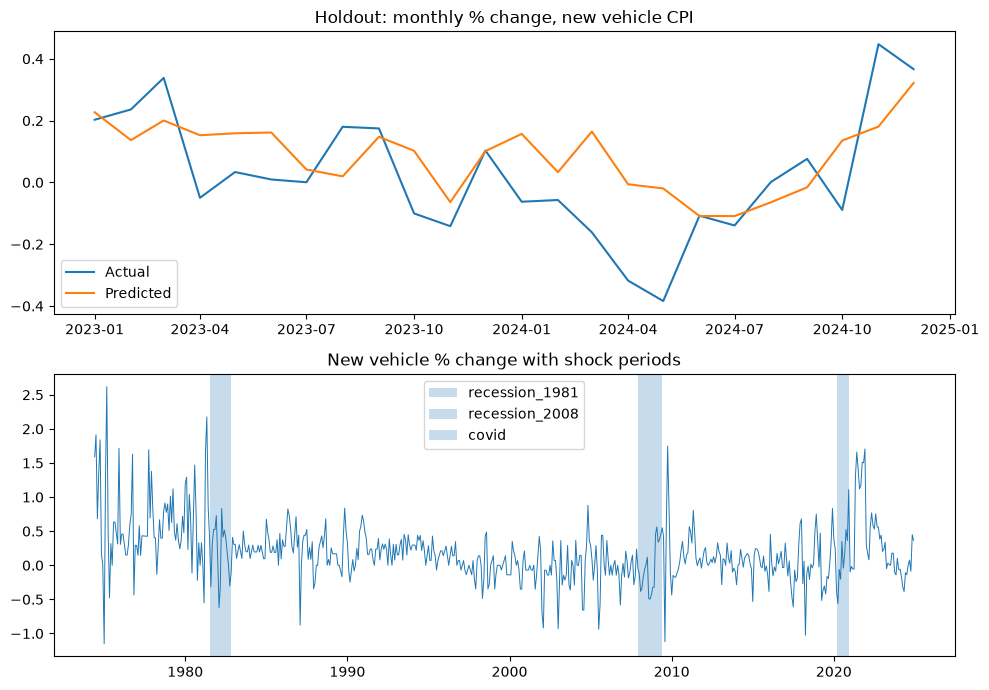

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(test[TARGET], label="Actual")
ax[0].plot(pd.Series(pred, index=test.index), label="Predicted")
ax[0].set_title("Holdout: monthly % change, new vehicle CPI")
ax[0].legend()

ax[1].plot(pchg[TARGET], lw=0.7)
for name, (s, e) in SHOCKS.items():
    ax[1].axvspan(pd.Timestamp(s), pd.Timestamp(e), alpha=0.25, label=name)
ax[1].set_title("New vehicle % change with shock periods")
ax[1].legend()
plt.tight_layout()
plt.savefig("results.png", dpi=150)